# EN3160 ASSIGNMENT 02
## FITTING AND ALIGNMENT

**Name:** M.R.A.Hakam  
**Index number:** 230224V

In [1]:
import json
from pathlib import Path

import cv2 as cv
import numpy as np
from scipy.ndimage import maximum_filter
from IPython.display import HTML, Image, display

ROOT = Path.cwd()
synthetic = json.loads((ROOT / "results/q1/synthetic_circle.json").read_text())
sunflower = json.loads((ROOT / "results/q1/sunflower_circles.json").read_text())
line = json.loads((ROOT / "results/q2/line_fit.json").read_text())
circle = json.loads((ROOT / "results/q2/circle_fit.json").read_text())


## QUESTION 1  BLOB DETECTION

### SYNTHETIC CIRCLE

The LoG filter was first checked using a circle with radius 14 and centre at (35, 35). The selected sigma was 10 and the estimated radius was 14.14 pixels, giving a radius error of 0.14 pixels

The same filter was then applied at several sizes to the sunflower image

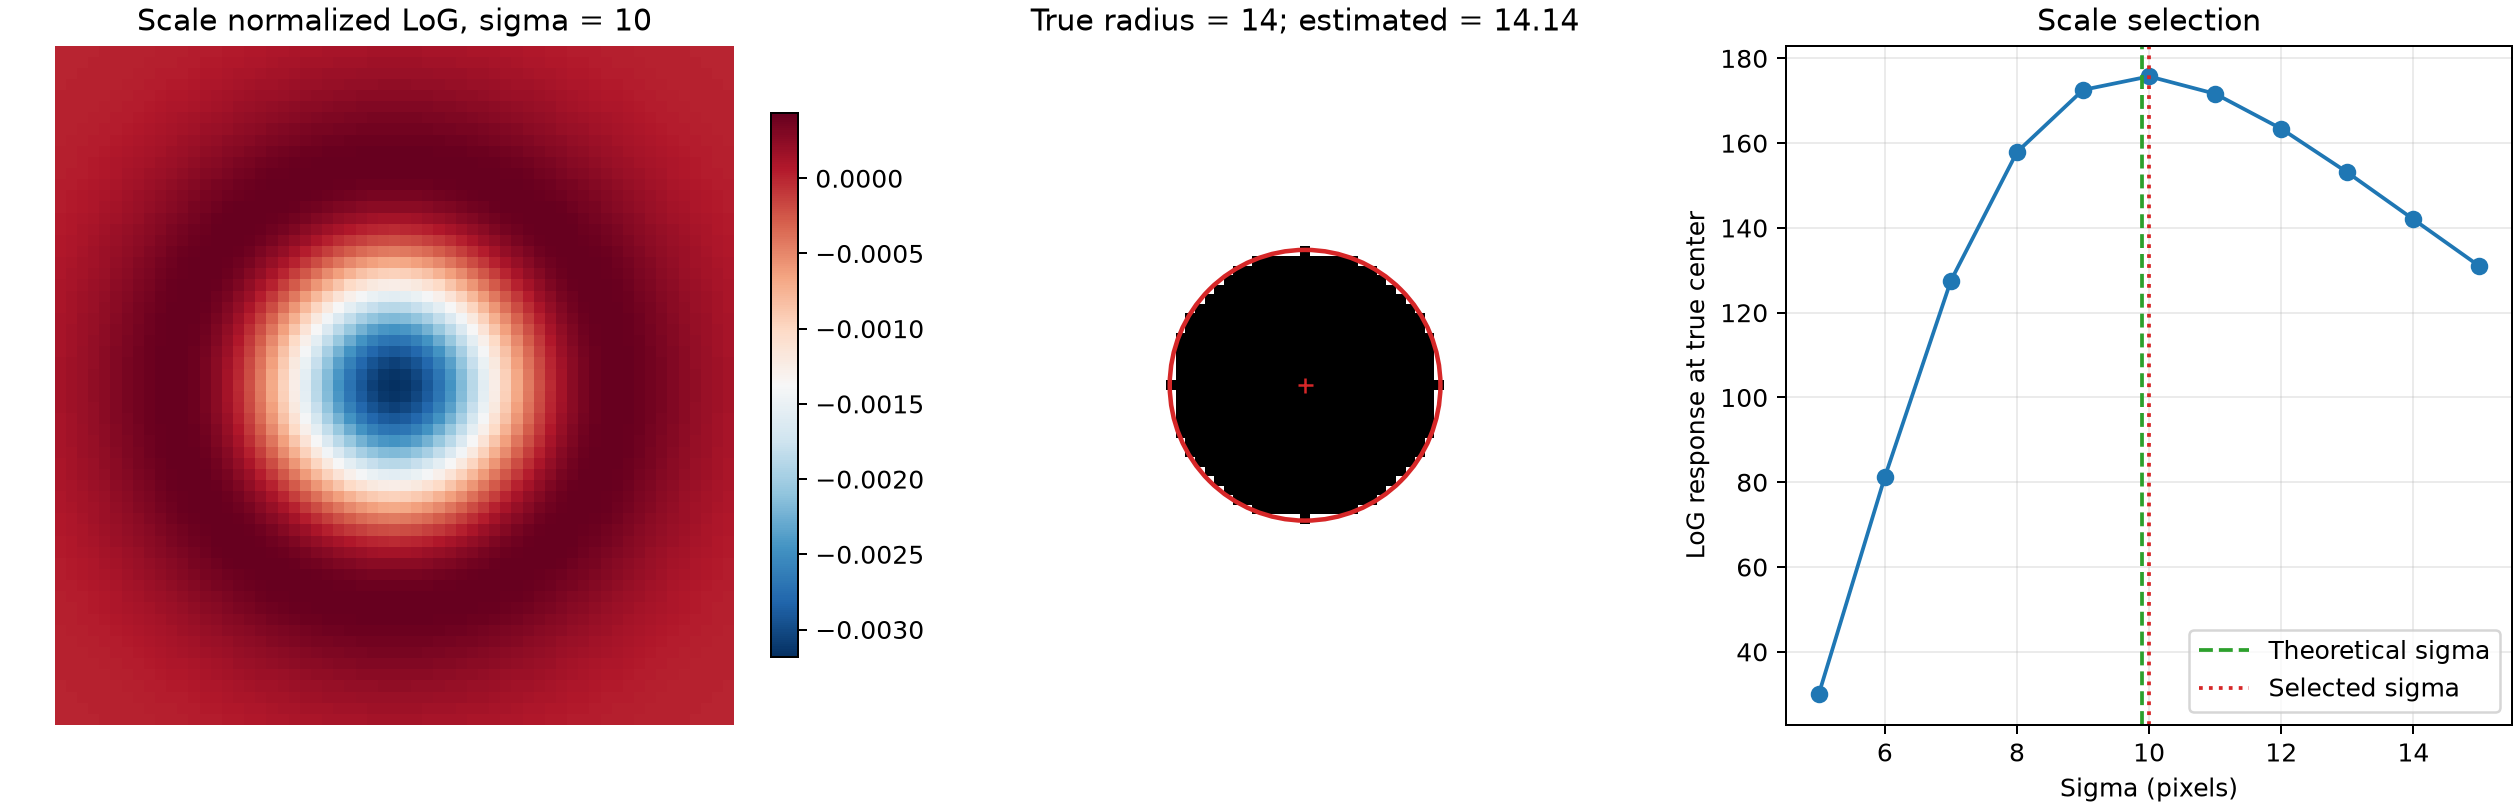

In [2]:
def normalized_log_kernel(sigma):
    if not np.isfinite(sigma) or sigma <= 0:
        raise ValueError("Sigma must be positive and finite")

    half_width = int(np.ceil(3 * sigma))
    coordinates = np.arange(-half_width, half_width + 1, dtype=np.float64)
    x, y = np.meshgrid(coordinates, coordinates)
    squared_distance = x**2 + y**2
    kernel = (
        (squared_distance / sigma**2 - 2)
        * np.exp(-squared_distance / (2 * sigma**2))
        / (2 * np.pi * sigma**2)
    )
    return kernel.astype(np.float32)

display(Image(filename=str(ROOT / "results/q1/synthetic_circle.png"), width=620))


In [3]:
image = cv.imread(str(ROOT / "images/the_berry_farms_sunflower_field.jpeg"), cv.IMREAD_REDUCED_COLOR_4)
gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0
sigmas = np.array(sunflower["sigma_values"])
scale_space = np.stack([cv.filter2D(gray, cv.CV_32F, normalized_log_kernel(sigma)) for sigma in sigmas], axis=2)
maxima = (scale_space == maximum_filter(scale_space, size=3, mode="nearest")) & (scale_space >= sunflower["response_threshold"])
maxima[:, :, [0, -1]] = False
assert int(maxima.sum()) == sunflower["candidate_count"]
print(f"Image size: {image.shape[1]} by {image.shape[0]}")
print(f"Sigma range: {sigmas[0]:g} to {sigmas[-1]:g} with step 0.5")
print(f"Final detected circles: {sunflower['detected_count']}")


Image size: 360 by 360
Sigma range: 1 to 12 with step 0.5
Final detected circles: 65


### SUNFLOWER DETECTION

Positive LoG responses were used to find the dark flower centres. Each candidate was compared with its neighbours in image position and scale. The response threshold was 0.22 after scaling the image values to 0 to 1

A yellow pixel check around each candidate removed many tree and leaf responses. At least 35% of the ring from one radius to 2.2 radii had to pass this check

The stronger response was kept when circle centres were closer than 0.6 times the sum of their radii. Circles crossing the image edge and peaks at the first or last scale were excluded

### RESULTS

The radii below describe the dark centres and do not include the outer petals

Circle,x,y,Radius,Sigma
1,282,338,10.61,7.5
2,106,255,8.49,6
3,179,327,8.49,6
4,178,261,7.78,5.5
5,161,290,6.36,4.5


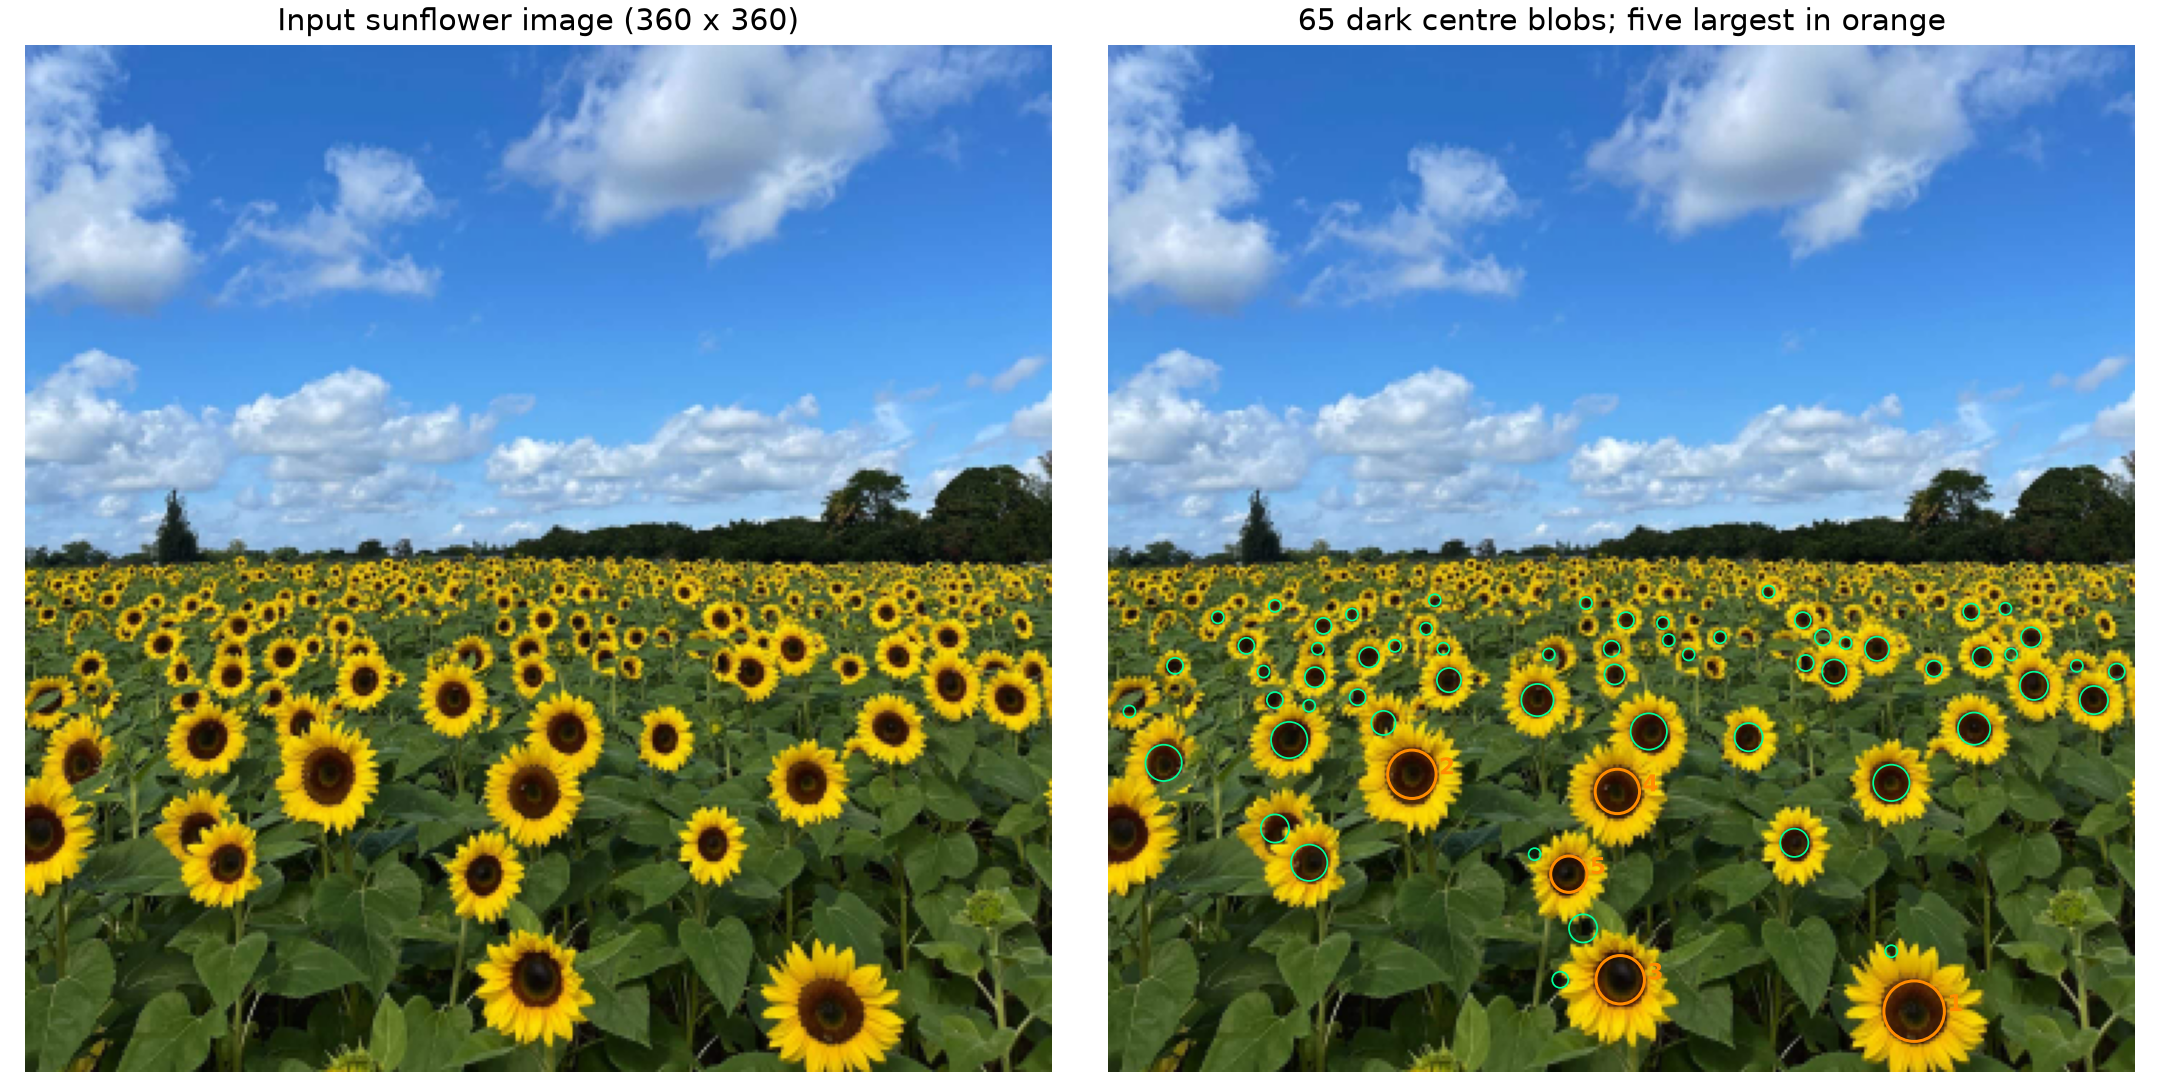

In [4]:
rows = "".join(f"<tr><td>{i}</td><td>{c['x']}</td><td>{c['y']}</td><td>{c['radius']:.2f}</td><td>{c['sigma']:g}</td></tr>" for i, c in enumerate(sunflower["largest_circles"], 1))
display(HTML("<table><tr><th>Circle</th><th>x</th><th>y</th><th>Radius</th><th>Sigma</th></tr>" + rows + "</table>"))
display(Image(filename=str(ROOT / "results/q1/sunflower_detection.png"), width=720))


There are 65 detections and the five largest are marked in orange. The largest centre is at (282, 338) with radius 10.61 pixels. All positions and radii use the reduced 360 by 360 image

The filter finds clear foreground centres but misses some small distant flowers. Nearby flowers can also merge during duplicate removal

## QUESTION 2  LINE AND CIRCLE FITTING

### LINE FITTING

The point generator uses seed 0 and gives 50 noisy circle points and 50 noisy line points. Two different points form a line sample and perpendicular distance is used to find its inliers

The line is written as ax + by = d with a squared plus b squared equal to 1. The line threshold is 1.4, the minimum consensus is 40 and the loop uses 500 samples. This threshold is about twice the expected perpendicular noise of 0.71

In [5]:
def fit_line(points):
    center = points.mean(axis=0)
    _, _, vectors = np.linalg.svd(points - center, full_matrices=False)
    normal = vectors[-1]
    model = np.append(normal, normal @ center)
    return -model if model[2] < 0 else model

def circle_from_points(points):
    offsets = points[1:] - points[0]
    matrix = 2 * offsets
    if np.linalg.cond(matrix) > 1e8:
        raise ValueError("The circle sample is too close to a straight line")
    right = np.sum(offsets**2, axis=1)
    relative_center = np.linalg.solve(matrix, right)
    center = points[0] + relative_center
    radius = np.linalg.norm(relative_center)
    model = np.append(center, radius)
    if not np.isfinite(model).all() or radius < 1e-10:
        raise ValueError("The circle sample is invalid")
    return model

def circle_errors(points, model):
    return np.abs(np.linalg.norm(points - model[:2], axis=1) - model[2])


### CIRCLE FITTING

The line consensus is removed before fitting the circle. Three points form a circle sample and radial distance is used to find its inliers. The circle threshold is 1.25, the minimum consensus is 30 and the loop uses 500 samples. This threshold is twice the radial noise level of 0.625 in the point generator

Both loops prefer the larger consensus and use the smaller mean squared error to break a tie. The line is refined by total least squares and the circle is refined by minimizing squared radial errors

### RESULTS

The winning samples and their models are shown together with the refined models

Line parameters (a, b, d): [0.721  0.693  1.5724]
Line normal length: 1.000000
Line inliers: 54 of 100
Circle parameters (x, y, radius): [1.8982 3.0101 9.8314]
Circle inliers: 44 of 46


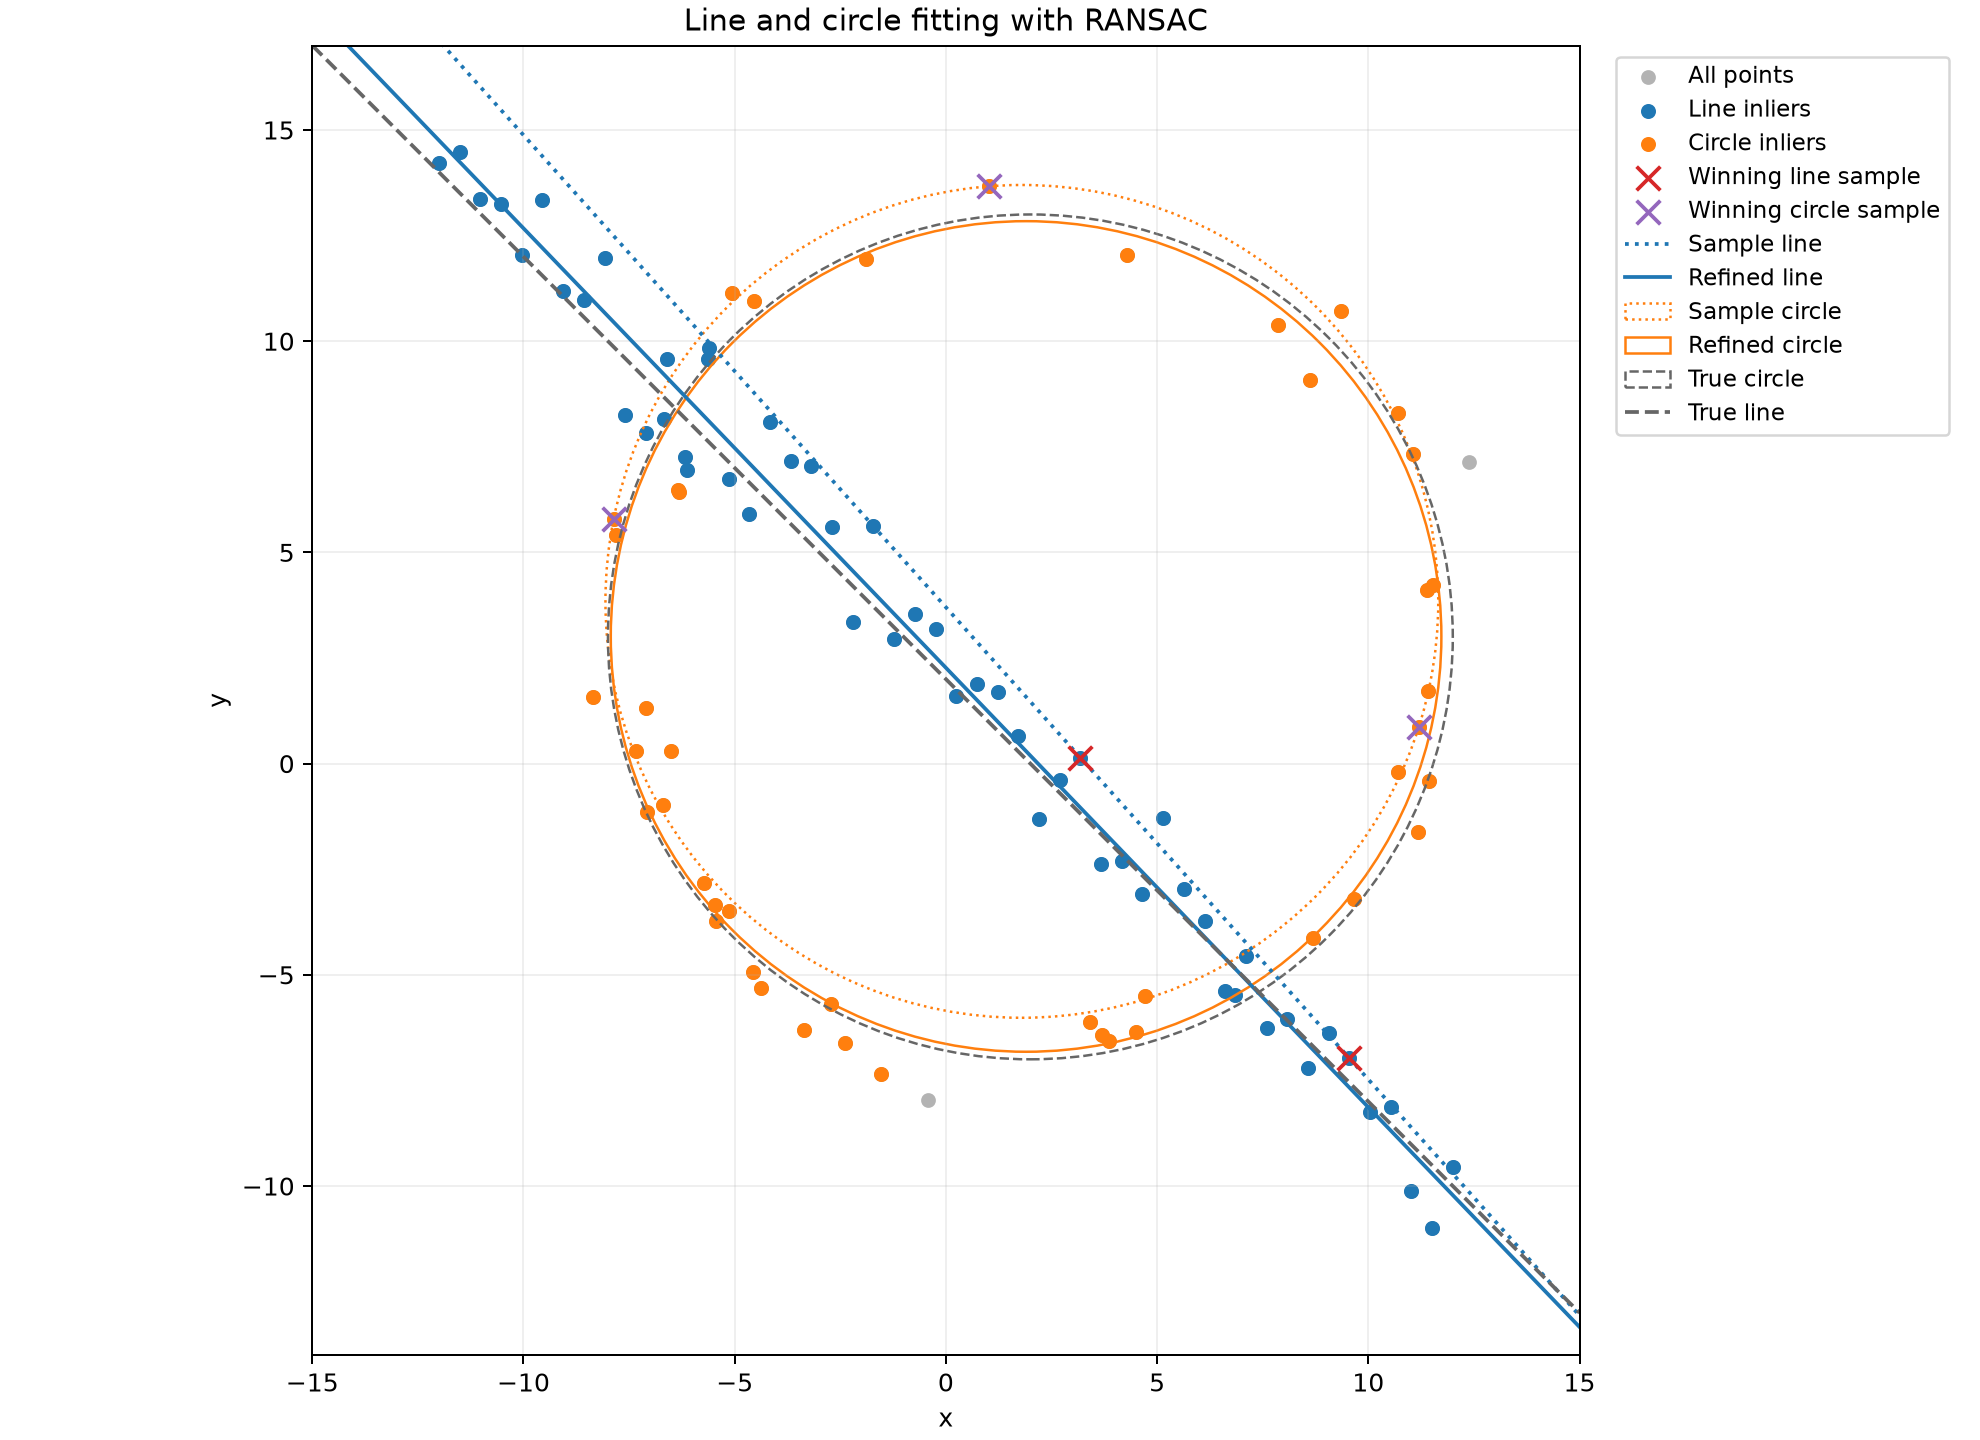

In [6]:
points = np.loadtxt(ROOT / "results/q2/points.csv", delimiter=",", skiprows=1)
line_model = np.array(line["model"])
circle_model = np.array(circle["model"])
line_indices = np.array(line["inlier_indices"])
circle_indices = np.array(circle["inlier_indices"])
normal_length = np.linalg.norm(line_model[:2])
assert np.isclose(normal_length, 1)
assert not set(line_indices) & set(circle_indices)
assert np.allclose(fit_line(points[line_indices]), line_model)
assert np.allclose(circle_from_points(points[circle["sample_indices"]]), circle["sample_model"])
assert np.all(circle_errors(points[circle_indices], circle_model) <= circle["threshold"])
print(f"Line parameters (a, b, d): {line_model.round(4)}")
print(f"Line normal length: {normal_length:.6f}")
print(f"Line inliers: {line['inlier_count']} of {len(points)}")
print(f"Circle parameters (x, y, radius): {circle_model.round(4)}")
print(f"Circle inliers: {circle['inlier_count']} of {circle['input_point_count']}")
display(Image(filename=str(ROOT / "results/q2/line_and_circle.png"), width=620))


The line consensus contains all 50 generated line points and four nearby circle points. Those four circle points are close to the line and are removed with its consensus. The circle fit uses the remaining 46 points and keeps 44 as inliers

The estimated circle centre is (1.90, 3.01) and its radius is 9.83, compared with the true centre (2, 3) and radius 10. The centre error is about 0.10 and the radius error is about 0.17. The line inlier RMSE is 0.67 and the circle inlier RMSE is 0.53

The generated labels were used only to check the result afterwards and were not used by RANSAC